# 04 Training

Train a baseline segmentation model on the data.

Steps so far:
1. Data load
2. Small U-Net
3. Loss and optimizer
4. Validation metrics: IoU and F1
5. Training
6. Learning curves
7. Visualization

#### Step 1: Data loader

- Training data is shuffled each epoch, validation data is not. 
- Four worker processes load the files in parallel to improve speed

- The train split uses `augment=True`: random flips and 90-degree rotations,
applied to image and mask together (see `landslide_analysis/data.py`). Val
data is never augmented.

In [1]:
from torch.utils.data import DataLoader

from landslide_analysis import Landslide4SenseDataset, get_data_dir

data_dir = get_data_dir()

train_ds = Landslide4SenseDataset(data_dir, "train", "splits.json", "normalisation_stats.json",
                                  augment=True)
val_ds = Landslide4SenseDataset(data_dir, "val", "splits.json", "normalisation_stats.json")

batch_size = 16
train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                          num_workers=4, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=batch_size,
                        num_workers=4, persistent_workers=True)

print(f"train: {len(train_ds)} images -> {len(train_loader)} batches of {batch_size}")
print(f"val:   {len(val_ds)} images -> {len(val_loader)} batches of {batch_size}")

train: 2659 images -> 167 batches of 16
val:   570 images -> 36 batches of 16


#### Step 2: Model — a small U-Net

The standard architecture for segmentation, kept as small as possible:

- **Down path:** two encoder levels
- **Up path:** mirrors the down path; each level upsamples and concatenates the
  matching encoder output (the "skip connection")
- **Head:** a 1x1 convolution producing one logit per pixel (no sigmoid here —
  the loss applies it)

Input `(B, 14, 128, 128)` -> output `(B, 128, 128)`.

In [2]:
import torch
import torch.nn as nn


def conv_block(in_ch, out_ch):
    """Two 3x3 convolutions, each followed by batch norm and ReLU."""
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
    )


class SmallUNet(nn.Module):
    def __init__(self, in_channels=14):
        super().__init__()
        self.enc1 = conv_block(in_channels, 32)   # 128x128
        self.enc2 = conv_block(32, 64)            # 64x64
        self.bottleneck = conv_block(64, 128)     # 32x32
        self.pool = nn.MaxPool2d(2)

        self.up2 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.dec2 = conv_block(128, 64)           # 64 up + 64 skip
        self.up1 = nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2)
        self.dec1 = conv_block(64, 32)            # 32 up + 32 skip
        self.head = nn.Conv2d(32, 1, kernel_size=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        b = self.bottleneck(self.pool(e2))

        d2 = self.dec2(torch.cat([self.up2(b), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1).squeeze(1)  # (B, 1, 128, 128) -> (B, 128, 128)


torch.manual_seed(42)  # reproducible weight initialization
model = SmallUNet()
n_params = sum(p.numel() for p in model.parameters())
print(f"SmallUNet with {n_params:,} parameters")

SmallUNet with 470,977 parameters


#### Step 3: Loss and optimizer

- Only ~2% of all pixels are landslide (finding from notebook 01), so plain Binary Cross-Entropy
would let the model predict "no landslide" everywhere. 

- Add `pos_weight`: every landslide pixel counts as much in the loss as
~`pos_weight` background pixels.

Note: From here on Apple GPU (`mps`) is used

In [3]:
# pos_weight = background pixels / landslide pixels, counted on the train split
landslide = 0
total = 0
for _, mask in train_ds:
    landslide += mask.sum().item()
    total += mask.numel()

pos_weight = (total - landslide) / landslide
print(f"landslide pixels: {landslide / total * 100:.2f}%  ->  pos_weight = {pos_weight:.1f}")

device = "mps" if torch.backends.mps.is_available() else "cpu"
print(f"device: {device}")

model = model.to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=3e-4)

landslide pixels: 2.31%  ->  pos_weight = 42.3
device: mps


In [4]:
# Sanity check: one forward/backward pass on a single batch
images, masks = next(iter(train_loader))
images, masks = images.to(device), masks.to(device)

logits = model(images)
loss = loss_fn(logits, masks)
loss.backward()
optimizer.zero_grad()

print(f"input {tuple(images.shape)} -> logits {tuple(logits.shape)}")
print(f"loss on untrained model: {loss.item():.4f}")

input (16, 14, 128, 128) -> logits (16, 128, 128)
loss on untrained model: 2.6288


#### Step 4: Validation metrics — IoU and F1

- **IoU** (intersection over union): overlap between predicted and true
  landslide pixels, divided by their union. 0 = no overlap, 1 = gold standard.
- TODO: Add **F1 / Dice:** 

<!-- Counts are accumulated over the whole set (not averaged per image), so empty
masks don't distort the score.
Accuracy is useless here: predicting "no landslide" everywhere is already ~98%
accurate. Instead we score only the landslide class: -->

In [5]:
@torch.no_grad()
def evaluate(model, loader):
    """Average loss, IoU and F1 for the landslide class over a whole loader."""
    model.eval()
    total_loss = 0.0
    tp = fp = fn = 0
    for images, masks in loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        total_loss += loss_fn(logits, masks).item() * images.shape[0]

        pred = logits.sigmoid() > 0.5
        true = masks.bool()
        tp += (pred & true).sum().item()
        fp += (pred & ~true).sum().item()
        fn += (~pred & true).sum().item()

    iou = tp / (tp + fp + fn)
    f1 = 2 * tp / (2 * tp + fp + fn)
    return total_loss / len(loader.dataset), iou, f1


val_loss, val_iou, val_f1 = evaluate(model, val_loader)
print(f"untrained model: val loss {val_loss:.4f}  IoU {val_iou:.3f}  F1 {val_f1:.3f}")

untrained model: val loss 1.3509  IoU 0.014  F1 0.028


#### Step 5: Training

- For each epoch: one pass over the training data with gradient updates, then
loss + IoU + F1 on the validation set. 
- Whenever the val IoU improves, the model weights are saved to `../models/unet_baseline.pt` 
- (= keeping the best model, not the latest)

In [6]:
from pathlib import Path
import time

epochs = 30
checkpoint = Path("../models/unet_baseline.pt")
checkpoint.parent.mkdir(exist_ok=True)

history = {"train_loss": [], "val_loss": [], "val_iou": [], "val_f1": []}
best_iou = 0.0

for epoch in range(1, epochs + 1):
    start = time.time()
    model.train()
    running = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images), masks)
        loss.backward()
        optimizer.step()
        running += loss.item() * images.shape[0]

    train_loss = running / len(train_ds)
    val_loss, val_iou, val_f1 = evaluate(model, val_loader)
    for key, value in zip(history, [train_loss, val_loss, val_iou, val_f1]):
        history[key].append(value)

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), checkpoint)
        saved = "  <- best so far, saved"

    print(f"epoch {epoch:2d}/{epochs}  "
          f"train loss {train_loss:.4f}  val loss {val_loss:.4f}  "
          f"val IoU {val_iou:.3f}  val F1 {val_f1:.3f}  "
          f"({time.time() - start:.0f}s){saved}")

print(f"\nbest val IoU: {best_iou:.3f} -> {checkpoint}")

epoch  1/30  train loss 0.5948  val loss 0.4317  val IoU 0.250  val F1 0.400  (12s)  <- best so far, saved


epoch  2/30  train loss 0.3949  val loss 0.3436  val IoU 0.273  val F1 0.429  (12s)  <- best so far, saved


epoch  3/30  train loss 0.3268  val loss 0.3041  val IoU 0.244  val F1 0.393  (12s)


epoch  4/30  train loss 0.2841  val loss 0.2435  val IoU 0.283  val F1 0.441  (12s)  <- best so far, saved


epoch  5/30  train loss 0.2867  val loss 0.2413  val IoU 0.284  val F1 0.442  (12s)  <- best so far, saved


epoch  6/30  train loss 0.2480  val loss 0.2372  val IoU 0.260  val F1 0.413  (12s)


... (20 outputs left out)

epoch 27/30  train loss 0.1794  val loss 0.1830  val IoU 0.365  val F1 0.534  (12s)


epoch 28/30  train loss 0.1825  val loss 0.1839  val IoU 0.328  val F1 0.494  (12s)


epoch 29/30  train loss 0.1812  val loss 0.1895  val IoU 0.374  val F1 0.544  (12s)


epoch 30/30  train loss 0.1759  val loss 0.1811  val IoU 0.334  val F1 0.500  (12s)

best val IoU: 0.380 -> ../models/unet_baseline.pt


#### Step 6: Learning curves

Train vs. val loss shows over/underfitting; val IoU shows whether the model
actually got better at finding landslides.

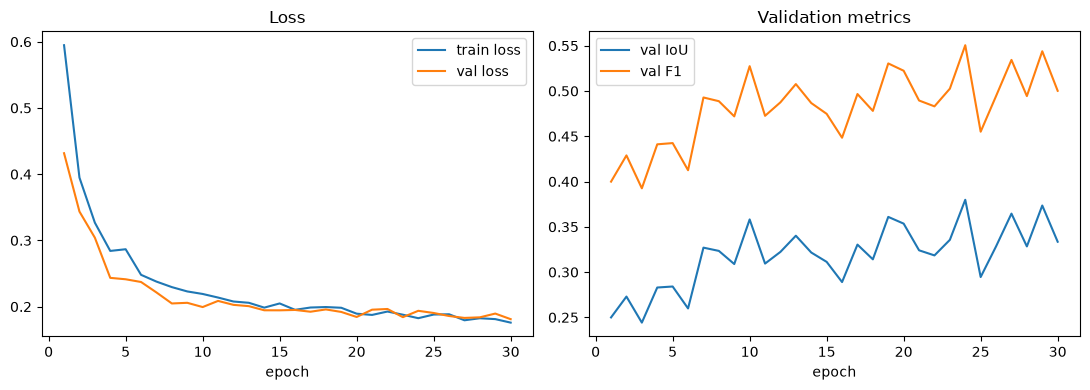

In [7]:
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(epochs_range, history["train_loss"], label="train loss")
axes[0].plot(epochs_range, history["val_loss"], label="val loss")
axes[0].set_xlabel("epoch")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(epochs_range, history["val_iou"], label="val IoU")
axes[1].plot(epochs_range, history["val_f1"], label="val F1")
axes[1].set_xlabel("epoch")
axes[1].set_title("Validation metrics")
axes[1].legend()

plt.tight_layout()
plt.show()

#### Step 7: Sanity Check and visualization

- Load the best checkpoint and compare predictions with ground truth on a few
validation samples: 
- RGB composite | true mask | predicted mask.
<!-- This catches
failure modes a single number hides (blurred boundaries, missed small slides,
false alarms). -->

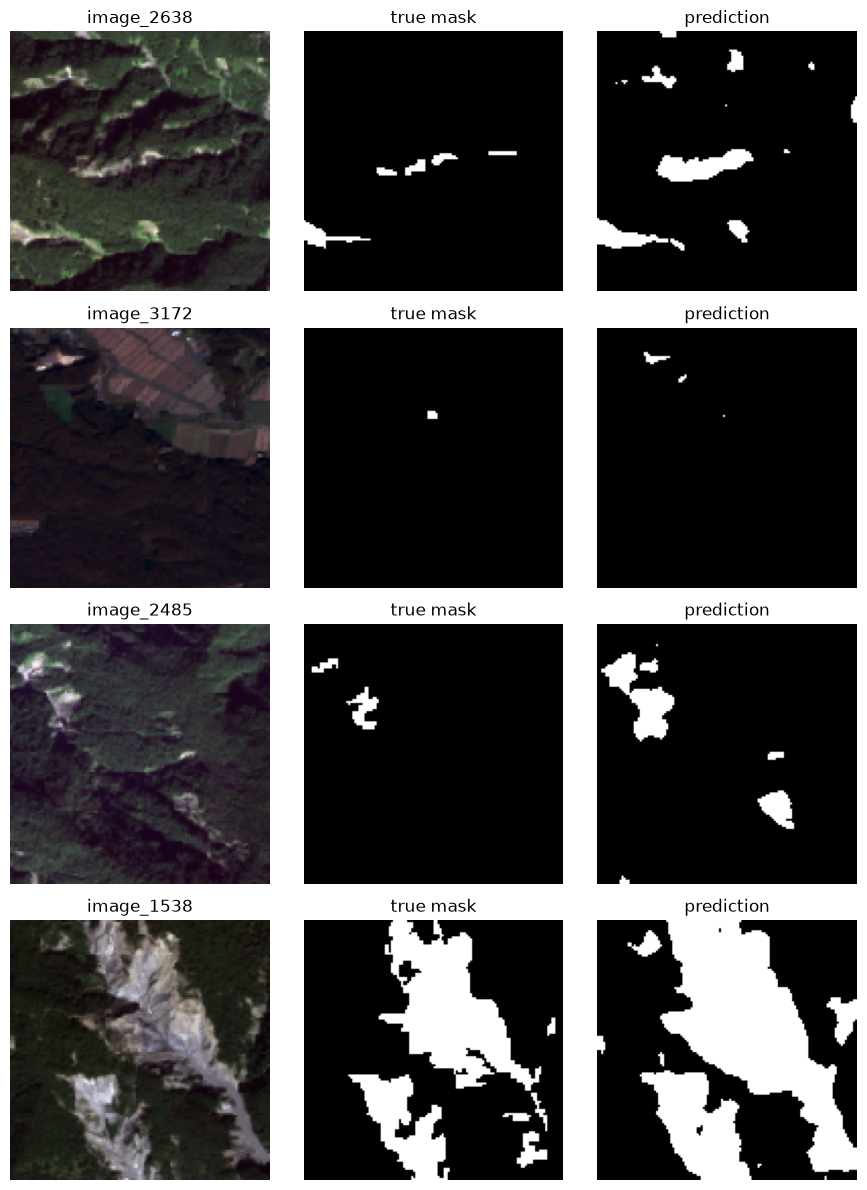

In [8]:
model.load_state_dict(torch.load(checkpoint, map_location=device))
model.eval()

# a few val samples that contain landslides
sample_indices = [i for i in range(len(val_ds)) if val_ds[i][1].sum() > 0][:4]

fig, axes = plt.subplots(len(sample_indices), 3, figsize=(9, 3 * len(sample_indices)))

for row, i in enumerate(sample_indices):
    image, mask = val_ds[i]
    with torch.no_grad():
        pred = (model(image.unsqueeze(0).to(device)).sigmoid() > 0.5).squeeze(0).cpu()

    rgb = image[[3, 2, 1]].permute(1, 2, 0)
    rgb = (rgb - rgb.min()) / (rgb.max() - rgb.min())

    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f"image_{val_ds.ids[i]}")
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("true mask")
    axes[row, 2].imshow(pred, cmap="gray")
    axes[row, 2].set_title("prediction")
    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()